In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# paste the path to dataset in local file system
df = pd.read_csv("paste_your_path_here")

## EDA

### Basic information

In [3]:
# Making EDA
print(df.columns)

for col in df.columns:
    print(col)
    # print unique 5 values
    print(df[col].unique()[:5])
    # print count of unique
    print(df[col].nunique())
    # add empty row
    print()


print(df.isnull().sum())

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')
person_age
[22 21 25 23 24]
58

person_income
[59000  9600 65500 54400  9900]
4295

person_home_ownership
<StringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str
4

person_emp_length
[123.   5.   1.   4.   8.]
36

loan_intent
<StringArray>
['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOMEIMPROVEMENT']
Length: 5, dtype: str
6

loan_grade
<StringArray>
['D', 'B', 'C', 'A', 'E']
Length: 5, dtype: str
7

loan_amnt
[35000  1000  5500  2500  1600]
753

loan_int_rate
[16.02 11.14 12.87 15.23 14.27]
348

loan_status
[1 0]
2

loan_percent_income
[0.59 0.1  0.57 0.53 0.55]
77

cb_person_default_on_file
<StringArray>
['Y', 'N']
Length: 2, dtype: str
2

cb_person_cred_hist_length
[3 2 4 8 7]
29

perso

### Columns
Let's brake down each column, and the meaning it has. I'm going to break down each column by next criterias:
1) meaning
2) max, min, avg, std values
3) missing values

#### person_age

In [4]:
# meaning is obvious
print("min = ", df["person_age"].min(), "\nmax = ", df["person_age"].max(), "\navg = ", df["person_age"].mean(), "\nstd = ", df["person_age"].std())

min =  20 
max =  144 
avg =  27.73459992019889 
std =  6.34807841922536


<Axes: xlabel='person_age', ylabel='Count'>

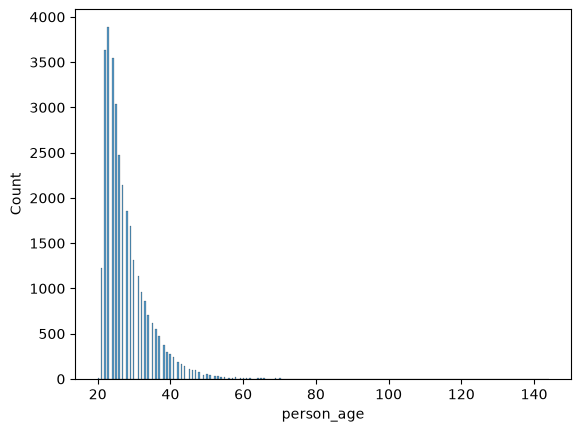

In [5]:
# max is 144, that should not be allowed at all. Let's plot the creditors age
%matplotlib inline

sns.histplot(df["person_age"])

In [6]:
# Let's count how much people are above 50, 60, 70, 80, 90, 100?
above_50 = len(df["person_age"][df["person_age"] > 50])
print("People above 50 are \n", above_50)

above_60 = len(df["person_age"][df["person_age"] > 60])
print("People above 60 are \n", above_60)

above_70 = len(df["person_age"][df["person_age"] > 70])
print("People above 70 are \n", above_70)

above_80 = len(df["person_age"][df["person_age"] > 80])
print("People above 80 are \n", above_80)

above_90 = len(df["person_age"][df["person_age"] > 90])
print("People above 90 are \n", above_90)

above_100 = len(df["person_age"][df["person_age"] > 100])
print("People above 100 are \n", above_100)

People above 50 are 
 288
People above 60 are 
 70
People above 70 are 
 13
People above 80 are 
 7
People above 90 are 
 6
People above 100 are 
 5


There are no missing values here. 

**Decision:** because of only 5 people, whose age are over 100 I'd rather replace all rows with people over 100 years old with median

In [7]:
# df = df[df["person_age"] <= 100] # first I decided to delete them, but then, changed my decision
# df.loc[df["person_age"] > 100, "person_age"] = df["person_age"].median()

#### person_income

min = 4000 
max = 6000000 
avg = 66074.84846996715 
std = 61983.11916815908


<Axes: xlabel='person_income', ylabel='Count'>

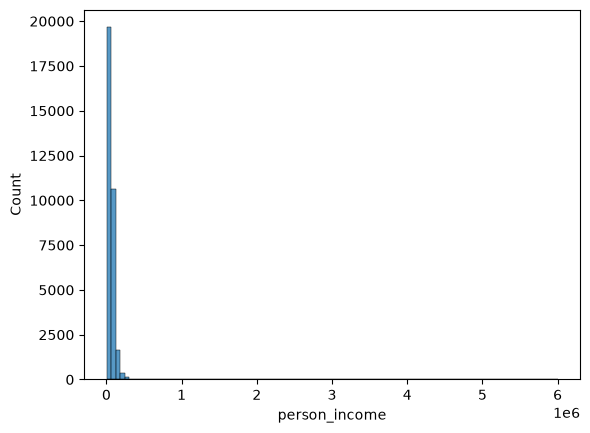

In [8]:
# meaning is obvious
# let's print statistics for this column
print("min =", df["person_income"].min(),
      "\nmax =", df["person_income"].max(),
      "\navg =", df["person_income"].mean(),
      "\nstd =", df["person_income"].std())

# let's plot the column
sns.histplot(df["person_income"], bins = 100)

32581
Below 200k: 32134, that is 98.63% 
Above 200k: 447, that is 1.37%


<Axes: xlabel='person_income', ylabel='Count'>

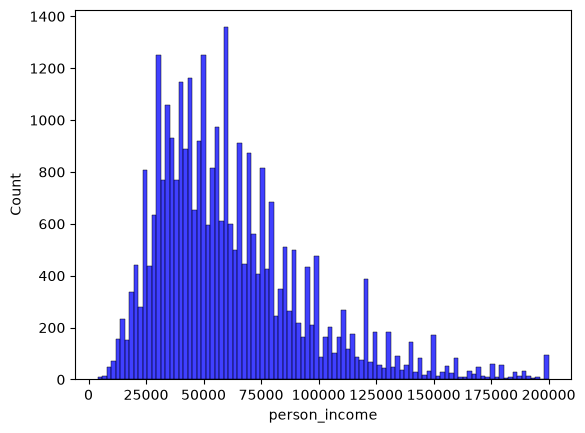

In [9]:
# Let's check amount of people beyond and above the 200k
print(df.shape[0])
beyond_200 = len(df[df["person_income"] <= 200000])
above_200 = len(df[df["person_income"] > 200000])
beyond_200_percentage = round((beyond_200 / df.shape[0]) * 100, 2)
above_200_percentage = round((above_200 / df.shape[0]) * 100, 2)
print(f"Below 200k: {beyond_200}, that is {beyond_200_percentage}%",
      f"\nAbove 200k: {above_200}, that is {above_200_percentage}%")

# and let's plot the data
sns.histplot(df["person_income"][df["person_income"] <= 200000], bins = 100, color="blue")
#sns.histplot(df["person_income"][df["person_income"] > 200000], bins = 100, color="red")

<Axes: xlabel='person_income', ylabel='Count'>

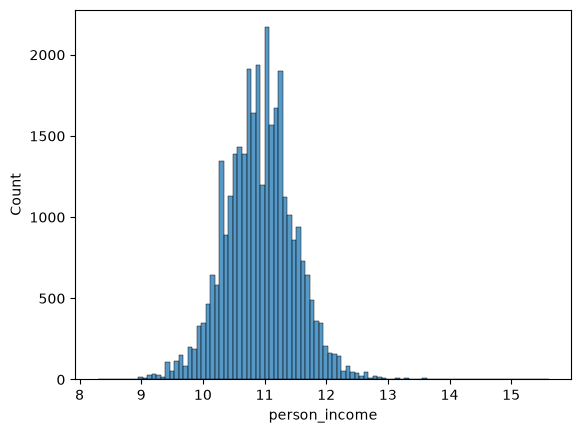

In [10]:
# As we see previously, income has very large numbers in it, so it would be beneficial for us to add logarithm on top of this feature
# column_person_income = np.log(df["person_income"])
sns.histplot(np.log(df["person_income"]), bins = 100)

There are no missing values here

**Decision:** because of very large range of values, add log to "person_income" column

In [11]:
df["person_income"] = np.log(df["person_income"])

#### person_home_ownership

person_home_ownership
RENT        50.48
MORTGAGE    41.26
OWN          7.93
OTHER        0.33
Name: proportion, dtype: float64


<Axes: xlabel='person_home_ownership', ylabel='Count'>

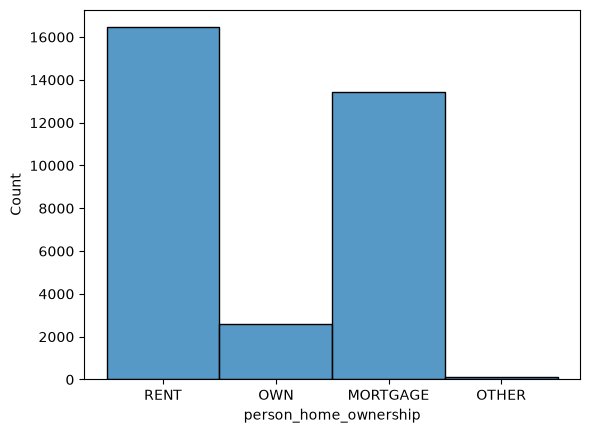

In [12]:
# meaning is obvious: Home ownership
# let's count values and %
print(round(df["person_home_ownership"].value_counts(normalize=True) * 100, 2))

# let's plot the column
sns.histplot(df["person_home_ownership"], bins = 10)

#### person_emp_length

min = 0.0 
max = 123.0 
avg = 4.789686296787225 
std = 4.1426301488878625


<Axes: xlabel='person_emp_length', ylabel='Count'>

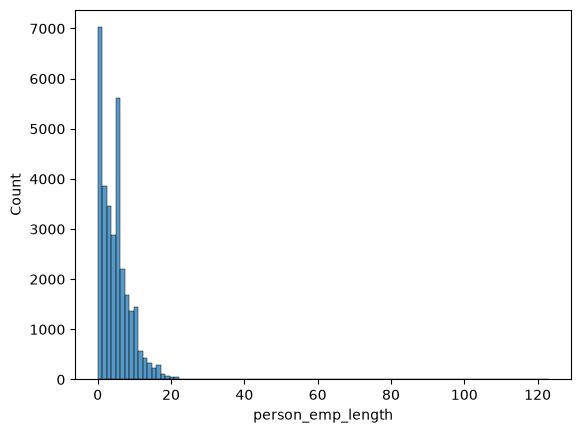

In [13]:
# meaning: how many years of employment person has
print("min =", df["person_emp_length"].min(),
      "\nmax =", df["person_emp_length"].max(),
      "\navg =", df["person_emp_length"].mean(),
      "\nstd =", df["person_emp_length"].std())

# let's plot the column
sns.histplot(df["person_emp_length"], bins = 100)

In [14]:
# again this 100+ values
print(f"people from 0 - 10 employment years: {len(df[df["person_emp_length"] <= 10])}",
      f"\npeople from 20 - 10 employment years: {len(df[(df["person_emp_length"] <= 20) & (df["person_emp_length"] > 10)])}",
      f"\npeople from 30 - 20 employment years: {len(df[(df["person_emp_length"] <= 30) & (df["person_emp_length"] > 20)])}",
      f"\npeople from 40 - 30 employment years: {len(df[(df["person_emp_length"] <= 40) & (df["person_emp_length"] > 30)])}",
      f"\npeople from 50 - 40 employment years: {len(df[(df["person_emp_length"] <= 50) & (df["person_emp_length"] > 40)])}",
      f"\npeople from 60 - 50 employment years: {len(df[(df["person_emp_length"] <= 60) & (df["person_emp_length"] > 50)])}",
      f"\npeople from 70 - 60 employment years: {len(df[(df["person_emp_length"] <= 70) & (df["person_emp_length"] > 60)])}",
      f"\npeople from 80 - 70 employment years: {len(df[(df["person_emp_length"] <= 80) & (df["person_emp_length"] > 70)])}",
      f"\npeople from 90 - 80 employment years: {len(df[(df["person_emp_length"] <= 90) & (df["person_emp_length"] > 80)])}",
      f"\npeople from 90 employment years: {len(df[df["person_emp_length"] > 90])}",
      )

people from 0 - 10 employment years: 28757 
people from 20 - 10 employment years: 2818 
people from 30 - 20 employment years: 102 
people from 40 - 30 employment years: 6 
people from 50 - 40 employment years: 1 
people from 60 - 50 employment years: 0 
people from 70 - 60 employment years: 0 
people from 80 - 70 employment years: 0 
people from 90 - 80 employment years: 0 
people from 90 employment years: 2


4.0
people from 0 - 10 employment years: 28759 
people from 20 - 10 employment years: 2818 
people from 30 - 20 employment years: 102 
people from 40 - 30 employment years: 6 
people from 50 - 40 employment years: 1 
people from 60 - 50 employment years: 0 
people from 60 employment years: 0


<Axes: xlabel='person_emp_length', ylabel='Count'>

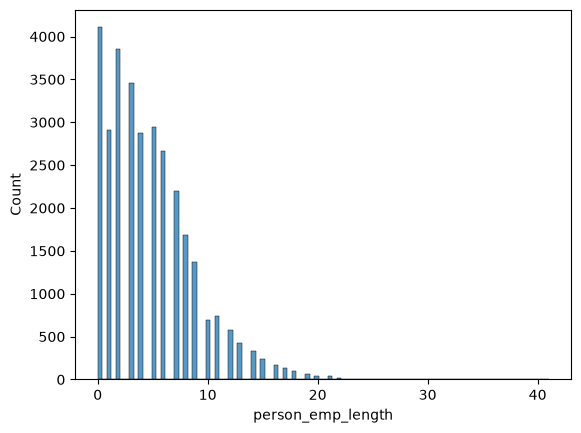

In [15]:
# yeah, so I think we could change all records over 60 with median, because we can't do it with 0 (this means absence of experience)
print(df["person_emp_length"].median())

# df["person_emp_length"] > 60 - create a boolean mask with True for values over 60
# df.loc[] - selects only rows where conditions is True in that column
# replaces with the median value
df1 = df
df1.loc[df1["person_emp_length"] > 60, "person_emp_length"] = df1["person_emp_length"].median()

print(f"people from 0 - 10 employment years: {len(df1[df1["person_emp_length"] <= 10])}",
      f"\npeople from 20 - 10 employment years: {len(df1[(df1["person_emp_length"] <= 20) & (df1["person_emp_length"] > 10)])}",
      f"\npeople from 30 - 20 employment years: {len(df1[(df1["person_emp_length"] <= 30) & (df1["person_emp_length"] > 20)])}",
      f"\npeople from 40 - 30 employment years: {len(df1[(df1["person_emp_length"] <= 40) & (df1["person_emp_length"] > 30)])}",
      f"\npeople from 50 - 40 employment years: {len(df1[(df1["person_emp_length"] <= 50) & (df1["person_emp_length"] > 40)])}",
      f"\npeople from 60 - 50 employment years: {len(df1[(df1["person_emp_length"] <= 60) & (df1["person_emp_length"] > 50)])}",
      f"\npeople from 60 employment years: {len(df1[df1["person_emp_length"] > 60])}"
      )
sns.histplot(df1["person_emp_length"], bins = 100)

In [16]:
# let's discover missing values
print(df["person_emp_length"].isnull().sum()) # around 895
# let's change them with median again
df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())

895


#### loan_intent

In [17]:
# meaning: purpose of taking the loan
print(round(df['loan_intent'].value_counts(normalize=True) * 100, 2))

loan_intent
EDUCATION            19.81
MEDICAL              18.63
VENTURE              17.55
PERSONAL             16.95
DEBTCONSOLIDATION    16.00
HOMEIMPROVEMENT      11.06
Name: proportion, dtype: float64


#### loan_grade

meaning: *Categorize borrowers by their crediworthiness, risk of default and corresponding interest rates*
- **A** - excellent credit history, strong income, low credit unilization => lowest available interest rate, highest approval likelihood
- **B** - good credit history with minor past hiccups => competitive interest rates, slightly higher than Grade A
- **C** - fair credit history, occasional payment overdue cycles (60+ days), higher debt-to-income ratios => standard or average interest rates; closer scrutiny from underwriters
- **D** - frequent late payments, high credit utilization (often >70%), limited credit history => higher interest rates and fees; automatic rejection thresholds at many tier-1 mainstream banks.
- **E** - repeated late payment cycles, multiple hard credit inquiries, or past restructured debt => significantly elevated interest rates; restricted loan amounts.
- **F** - active defaults, accounts sent to debt collections, or severe derogatory marks => very difficult to qualify for unsecured credit; high cost of borrowing if approved
- **G** - severe credit distress, multiple charge-offs, active legal/court judgments, or severe delinquency => rarely approved through conventional channels; reserved for specialized high-risk or secured options

In [18]:
print(round(df['loan_grade'].value_counts(normalize=True) * 100, 2))

loan_grade
A    33.08
B    32.08
C    19.82
D    11.13
E     2.96
F     0.74
G     0.20
Name: proportion, dtype: float64


#### loan_amnt

min = 500 
max = 35000 
avg = 9589.371105859243 
std = 6322.086645792259


<Axes: xlabel='loan_amnt', ylabel='Count'>

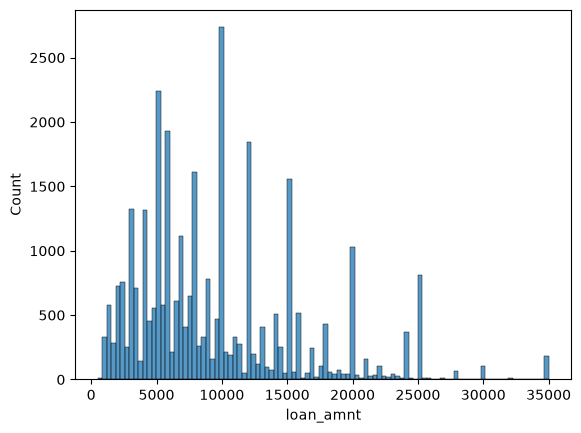

In [19]:
# meaning: how many years of employment person has
print("min =", df["loan_amnt"].min(),
      "\nmax =", df["loan_amnt"].max(),
      "\navg =", df["loan_amnt"].mean(),
      "\nstd =", df["loan_amnt"].std())

# let's plot the column
sns.histplot(df["loan_amnt"], bins = 100)

In [20]:
print(f"people from 0 - 5000 loan_amnt: {len(df[df["loan_amnt"] <= 5000])}",
      f"\npeople from 5000 - 10000 loan_amnt: {len(df[(df["loan_amnt"] <= 10000) & (df["loan_amnt"] > 5000)])}",
      f"\npeople from 10000 - 15000 loan_amnt: {len(df[(df["loan_amnt"] <= 15000) & (df["loan_amnt"] > 10000)])}",
      f"\npeople from 15000 - 20000 loan_amnt: {len(df[(df["loan_amnt"] <= 20000) & (df["loan_amnt"] > 15000)])}",
      f"\npeople from 20000 - 25000 loan_amnt: {len(df[(df["loan_amnt"] <= 25000) & (df["loan_amnt"] > 20000)])}",
      f"\npeople from 25000 - 30000 loan_amnt: {len(df[(df["loan_amnt"] <= 30000) & (df["loan_amnt"] > 25000)])}",
      f"\npeople from 30000 - 35000 loan_amnt: {len(df[(df["loan_amnt"] <= 35000) & (df["loan_amnt"] > 30000)])}"
      )

people from 0 - 5000 loan_amnt: 9489 
people from 5000 - 10000 loan_amnt: 12040 
people from 10000 - 15000 loan_amnt: 6123 
people from 15000 - 20000 loan_amnt: 2789 
people from 20000 - 25000 loan_amnt: 1689 
people from 25000 - 30000 loan_amnt: 231 
people from 30000 - 35000 loan_amnt: 220


**Decision**: I'd rather keep it as is, without transforming the column

#### loan_int_rate

min = 5.42 
max = 23.22 
avg = 11.011694892245037 
std = 3.2404594649559466


<Axes: xlabel='loan_int_rate', ylabel='Count'>

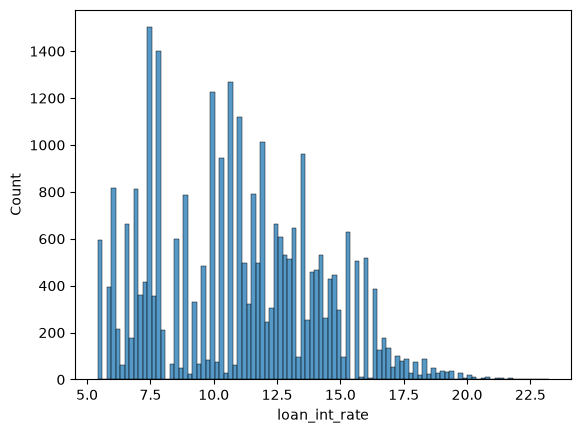

In [21]:
# meaning: interest rate
print("min =", df["loan_int_rate"].min(),
      "\nmax =", df["loan_int_rate"].max(),
      "\navg =", df["loan_int_rate"].mean(),
      "\nstd =", df["loan_int_rate"].std())

# let's plot the column
sns.histplot(df["loan_int_rate"], bins = 100)

In [22]:
# there are also missing values. Fill them with median
# loan_int_rate_median = df["loan_int_rate"].median()
# df["loan_int_rate"] = df["loan_int_rate"].fillna(loan_int_rate_median)

#### loan_status

loan_status
0    0.781836
1    0.218164
Name: proportion, dtype: float64


<Axes: xlabel='loan_status', ylabel='count'>

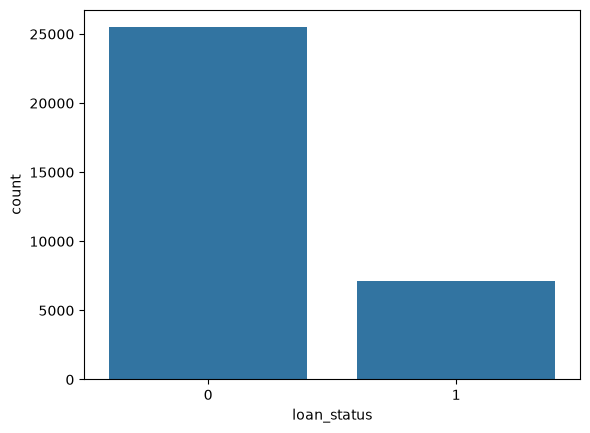

In [23]:
# loan status. What we must predict. 0 is non default, 1 - default
print(df['loan_status'].value_counts(normalize=True))
sns.countplot(data = df, x="loan_status")

#### loan_percent_income

min = 0.0 
max = 0.83 
avg = 0.17020349283324637 
std = 0.10678175634492382


<Axes: xlabel='loan_percent_income', ylabel='Count'>

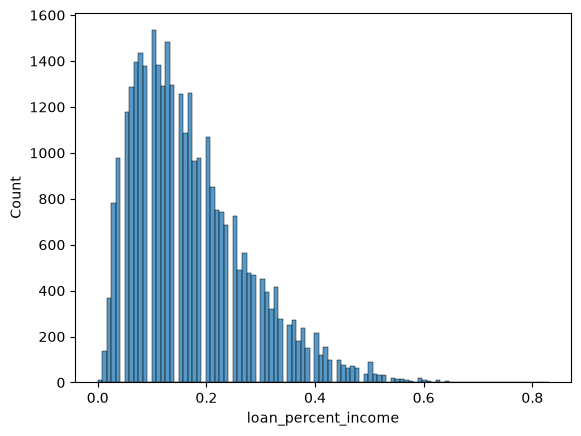

In [24]:
# meaning: how many years of employment person has
print("min =", df["loan_percent_income"].min(),
      "\nmax =", df["loan_percent_income"].max(),
      "\navg =", df["loan_percent_income"].mean(),
      "\nstd =", df["loan_percent_income"].std())

# let's plot the column
sns.histplot(df["loan_percent_income"], bins = 100)

#### cb_person_default_on_file

<Axes: xlabel='cb_person_default_on_file', ylabel='Count'>

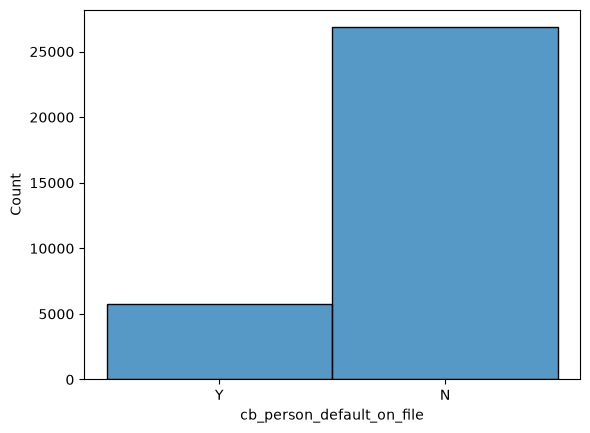

In [25]:
# meaning: historical default
# let's plot the column
sns.histplot(df["cb_person_default_on_file"], bins = 2)

#### cb_person_cred_hist_length

min = 2 
max = 30 
avg = 5.804211043246064 
std = 4.055001164712727


<Axes: xlabel='cb_person_cred_hist_length', ylabel='Count'>

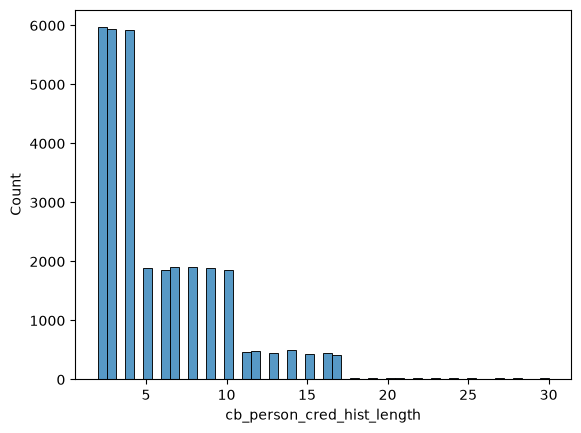

In [26]:
# meaning: credit history length in years
print("min =", df["cb_person_cred_hist_length"].min(),
      "\nmax =", df["cb_person_cred_hist_length"].max(),
      "\navg =", df["cb_person_cred_hist_length"].mean(),
      "\nstd =", df["cb_person_cred_hist_length"].std())

# let's plot the column
sns.histplot(df["cb_person_cred_hist_length"], bins = 50)

### Dependencies

In [27]:
print(df.dtypes)

person_age                      int64
person_income                 float64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object


In [28]:
from sklearn.metrics import mutual_info_score
# first, let's look at mutual information. This is a concept from information theory, 
# that tells us how much can we learn about one variable if we know the value of another

# let's save all string columns into a list

# df.dtypes[df.dtypes == 'str'] returns Series, .index extracts indices
column_text = list(df.dtypes[df.dtypes == 'str'].index)
print(type(column_text), column_text) #<class 'list'> ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']'

def mutual_info_y_score(series):
    return mutual_info_score(series, df["loan_status"])

print(df[column_text].apply(mutual_info_y_score))

# or same: 

for i in column_text:
    print(mutual_info_y_score(df[i]))

<class 'list'> ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
person_home_ownership        0.030677
loan_intent                  0.008076
loan_grade                   0.074487
cb_person_default_on_file    0.014507
dtype: float64
0.030676807201664352
0.008075832781448189
0.07448684967603912
0.014507338818275789


**Result:** there is no strong visible correlation between that variables and y

In [29]:
# take all numerical columns in a lis
numerical = list(df.dtypes[df.dtypes != 'str'].index)
mu = df[numerical].corrwith(df["loan_status"])
print(mu.sort_values(ascending=False))

loan_status                   1.000000
loan_percent_income           0.379366
loan_int_rate                 0.335133
loan_amnt                     0.105376
cb_person_cred_hist_length   -0.015529
person_age                   -0.021629
person_emp_length            -0.085630
person_income                -0.282810
dtype: float64


**Result:** there is no strong visible correlation between that variables and y

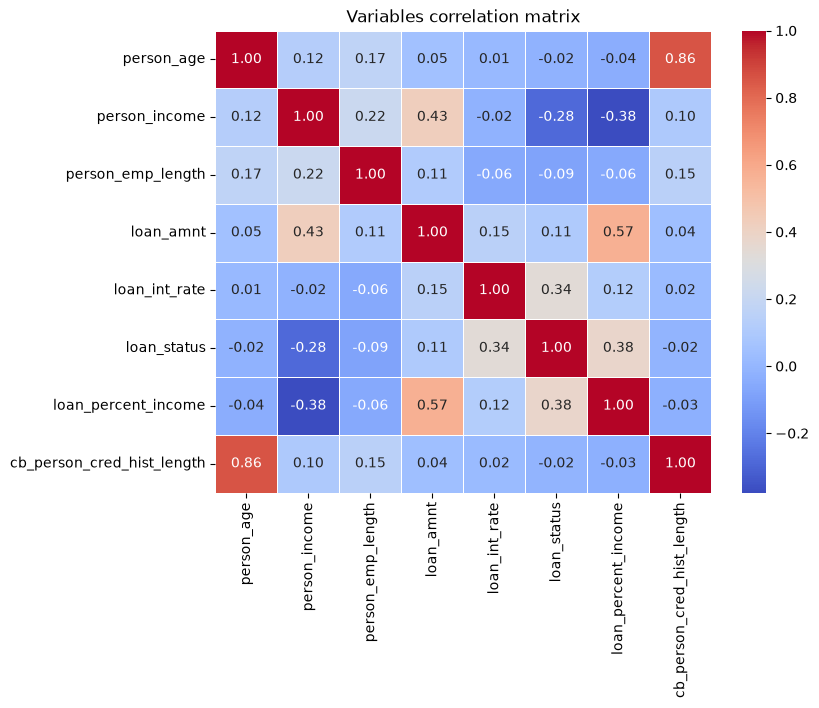

In [30]:
# let's take correlation between all variables. For this use pairwise Pearson correlation
corr_matrix = df[numerical].corr(method="pearson")
plt.figure(figsize = (8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Variables correlation matrix")
plt.show()

**Results:** 0.88 between *cb_person_cred_hist_length* and *person_age* exists. That might not be great for logistic regression. But, maybe it would be beneficial to train model without each of these features, or create a new one and test

# Building model pipeline

### Train test split

In [31]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

print("length of train + validation:", df_full_train.shape[0], 
      "\nlength of validation:", len(df_val),
      "\nlength of test:", len(df_test))

# reset indices in all data
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# get y-s
y_train = df_train["loan_status"]
y_val = df_val["loan_status"]
y_test = df_test["loan_status"]
y_full_train = df_full_train["loan_status"]

# delete y-s from X
del df_train["loan_status"]
del df_val["loan_status"]
del df_test["loan_status"]
del df_full_train["loan_status"]

length of train + validation: 26064 
length of validation: 6516 
length of test: 6517


### Data preprocessing for train and validation based on EDA

In [32]:
def data_preparing_train(df):
    df = df.copy()
    # After the EDA, i made several decisions:
    # 
    # 1) for person_age over 100, replace with median
    # 2) change person_income by logarithm it
    # 3) for person_emp_length over 60, replace with median
    # 4) for NaN in loan_int_rate, replace with median

    # all parameters will be stored in list 
    pp = {} # pp stays for 'preparation parameters'
    # 1)
    pp["person_age_median"] = df["person_age"].median()
    df.loc[df["person_age"] > 100, "person_age"] = pp["person_age_median"]

    # 2)
    df["person_income"] = np.log(df["person_income"])

    # 3)
    pp["person_emp_length_median"] = df["person_emp_length"].median()
    df.loc[df["person_emp_length"] > 60, "person_emp_length"] = pp["person_emp_length_median"]

    # 4)
    pp["loan_int_rate_median"] = df["loan_int_rate"].median()
    df["loan_int_rate"] = df["loan_int_rate"].fillna(pp["loan_int_rate_median"])

    return(df, pp)

def data_preparing_predict(df, pp):
    df = df.copy()
    # 1)
    df.loc[df["person_age"] > 100, "person_age"] = pp["person_age_median"]

    # 2)
    df["person_income"] = np.log(df["person_income"])

    # 3)
    df.loc[df["person_emp_length"] > 60, "person_emp_length"] = pp["person_emp_length_median"]

    # 4)
    df["loan_int_rate"] = df["loan_int_rate"].fillna(pp["loan_int_rate_median"])

    
    return(df)

# Training the model

## Logistic regression

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [34]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning) # in order to suppress the warning from scikit-learn

In [35]:
## find the best parameters
def train(df_train, y_train, C, max_iter):
    df_train, pp = data_preparing_train(df_train)

    # fit the DictVectorizer
    # get column names
    columns = df_train.columns.to_list()
    dicts = df_train[columns].to_dict(orient='records')
    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(max_iter=max_iter, C=C)
    model.fit(X_train, y_train)

    return dv, model, columns, pp

def predict(df_val, pp, dv, model, columns):
    df_val = data_preparing_predict(df_val, pp)

    dicts = df_val[columns].to_dict(orient='records')
    X_val = dv.transform(dicts)

    y_pred = model.predict_proba(X_val)[:, 1]

    return(y_pred)

scores = []
for max_iter in [100, 500, 1000, 5000, 10000, 15000, 20000]:
    for C in [0.001, 0.005, 0.01, 0.05, 0.1, 0.05, 1, 5, 10]:
        dict_vectorizer, model, columns, pp = train(df_train, y_train, C, max_iter)
        y_pred = predict(df_val, pp, dict_vectorizer, model, columns)
        auc = roc_auc_score(y_val, y_pred)
        scores.append((max_iter, C, auc))
    print(f"for {max_iter} done")

for score in sorted(scores, key=lambda x: x[2], reverse=True):
    print(score[:15])

del (C)
del (max_iter)

for 100 done
for 500 done
for 1000 done
for 5000 done
for 10000 done
for 15000 done
for 20000 done
(15000, 5, 0.8709896476240376)
(20000, 5, 0.8709896476240376)
(15000, 10, 0.8708378475583224)
(20000, 10, 0.8708378475583224)
(15000, 1, 0.8707401626897084)
(20000, 1, 0.8707401626897084)
(10000, 5, 0.8702790734590213)
(10000, 10, 0.8702539584572894)
(10000, 1, 0.8699375926896197)
(5000, 5, 0.8695364464464908)
(5000, 10, 0.86943834530713)
(5000, 1, 0.8693716032307051)
(15000, 0.1, 0.8657089756853481)
(20000, 0.1, 0.8657089756853481)
(10000, 0.1, 0.8655451037679718)
(5000, 0.1, 0.863511621169199)
(10000, 0.05, 0.8581821067962028)
(10000, 0.05, 0.8581821067962028)
(15000, 0.05, 0.8579449712273659)
(15000, 0.05, 0.8579449712273659)
(20000, 0.05, 0.8579449712273659)
(20000, 0.05, 0.8579449712273659)
(1000, 1, 0.856283773433268)
(5000, 0.05, 0.8560426139138775)
(5000, 0.05, 0.8560426139138775)
(1000, 0.1, 0.8508546315948388)
(500, 1, 0.8347165085207847)
(1000, 5, 0.832025040628025)
(1000, 0.05

**Result:** the best parameters are: 
- num_iter: 15000
- learning rate: 5 

Let's train the full train dataset on it, and test on validation

In [36]:
## actually train the model
dict_vectorizer, model, columns, pp = train(df_full_train, y_full_train, 5, 15000)
y_pred = predict(df_test, pp, dict_vectorizer, model, columns)
auc = roc_auc_score(y_test, y_pred)
print(auc)

0.8723748267167324


## Decision tree

In [37]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

for 1 done
for 2 done
for 3 done
for 4 done
for 5 done
for 6 done
for 10 done
for 15 done
for 20 done
for None done
(15, 30, 0.9147492079755255)
(10, 50, 0.9124660323070503)
(20, 50, 0.9109573977417034)
(None, 50, 0.91057997893115)
(10, 30, 0.9104825715763674)
(20, 30, 0.9103652526041898)
(None, 30, 0.9102380125125437)
(15, 50, 0.9101594067198311)
(10, 100, 0.9077910343051497)
(20, 100, 0.907633545205893)
(None, 100, 0.907633545205893)
(15, 100, 0.9073608184881935)
(15, 20, 0.9057161327670571)
(20, 200, 0.9047148628637652)
(None, 200, 0.9047148628637652)
(10, 20, 0.9046656041587109)
(15, 200, 0.9045178280435499)
(10, 1, 0.9043287023675259)
(10, 10, 0.9042319887973217)
(10, 15, 0.9041641366655715)
(10, 3, 0.9037932394300532)
(None, 20, 0.9032300251094514)
(20, 20, 0.9031694577157725)
(10, 200, 0.9026613992691396)
(20, 15, 0.9021564628531087)
(10, 5, 0.9018155371113695)
(None, 15, 0.9009802204791887)
(15, 10, 0.9005619377569779)
(15, 15, 0.9005149685410321)
(20, 10, 0.8959864284635947)
(

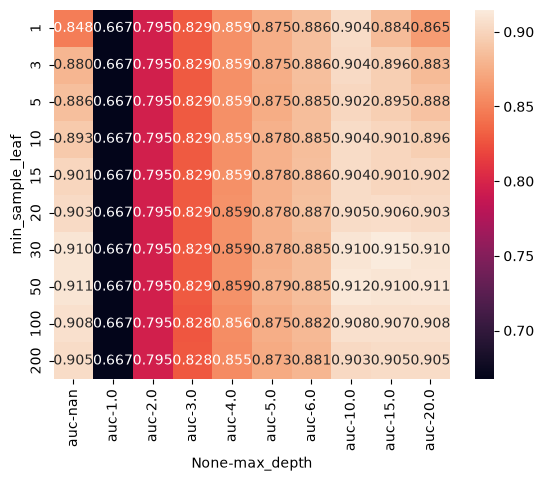

In [38]:
## find the best parameters
def train_dt(df_train, y_train, depth, min_sample_leaf):
    df_train, pp = data_preparing_train(df_train)

    # fit the DictVectorizer
    # get column names
    columns = df_train.columns.to_list()
    dicts = df_train[columns].to_dict(orient='records')
    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(dicts)

    model = DecisionTreeClassifier(max_depth = depth, min_samples_leaf = min_sample_leaf)
    model.fit(X_train, y_train)

    return dv, model, columns, pp

def predict_dt(df_val, pp, dv, model, columns):
    df_val = data_preparing_predict(df_val, pp)

    dicts = df_val[columns].to_dict(orient='records')
    X_val = dv.transform(dicts)

    y_pred = model.predict_proba(X_val)[:, 1]

    return(y_pred)

scores = []
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]
min_sample_leaves = [1, 3, 5, 10, 15, 20, 30, 50, 100, 200]

for depth in depths:
    for min_sample_leaf in min_sample_leaves:
        dict_vectorizer, model, columns, pp = train_dt(df_train, y_train, depth, min_sample_leaf)
        y_pred = predict_dt(df_val, pp, dict_vectorizer, model, columns)
        auc = roc_auc_score(y_val, y_pred)
        scores.append((depth, min_sample_leaf, auc))
    print(f"for {depth} done")

for score in sorted(scores, key=lambda x: x[2], reverse=True):
    print(score[:15])

columns = ['max_depth', 'min_sample_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_sample_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

del (depth)
del (min_sample_leaf)

**Result:** best model has next parameters:
- depth: 15
- min_sample_leaf: 30

In [39]:
# train the model with best parameters
dict_vectorizer, model, columns, pp = train_dt(df_train, y_train, 15, 30)
y_pred = predict_dt(df_test, pp, dict_vectorizer, model, columns)
auc = roc_auc_score(y_test, y_pred)
print(auc)

0.9050108881927238


## XGBoost

In [40]:
import xgboost as xgb

**Important** set number of nthread that suits your host!

In [41]:
nthread = 12
# find the best parameters
def train_xgboost(df_train, y_train, eta, max_depth, min_child_weight, nthread):
    df_train, pp = data_preparing_train(df_train)

    # fit the DictVectorizer
    # get column names
    columns = df_train.columns.to_list()
    dicts = df_train[columns].to_dict(orient='records')
    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(dicts)

    DX_train = xgb.DMatrix(X_train, label = y_train, feature_names = dv.get_feature_names_out().tolist())

    xgb_params = {
    'eta': eta,
    'max_depth': max_depth,
    'min_child_weight': min_child_weight,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': nthread,
    'seed': 1,
    'verbosity': 1,
    }

    model = xgb.train(xgb_params, DX_train)

    return dv, model, columns, pp


def predict_xgboost(df_val, pp, dv, model, columns):
    df_val = data_preparing_predict(df_val, pp)

    dicts = df_val[columns].to_dict(orient='records')
    X_val = dv.transform(dicts)

    DX_val = xgb.DMatrix(X_val, feature_names = dv.get_feature_names_out().tolist())

    y_pred = model.predict(DX_val)

    return(y_pred)

scores = []
etas = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]
depths = [1, 2, 3, 5, 10, 15, 30, 50, 100, 200]
min_child_weights = [1, 2, 3, 5, 10, 15, 30, 50]

for eta in etas:
    for depth in depths:
        for min_child_weight in min_child_weights:
            dict_vectorizer, model, columns, pp = train_xgboost(df_train, y_train, eta, depth, min_child_weight, nthread)
            y_pred = predict_xgboost(df_val, pp, dict_vectorizer, model, columns)
            auc = roc_auc_score(y_val, y_pred)
            scores.append((eta, depth, min_child_weight, auc))
        # print(f"depth {depth} done")
    print(f"eta {eta} done")

for score in sorted(scores, key=lambda x: x[3], reverse=True):
    print(score[:15])


eta 0.001 done
eta 0.005 done
eta 0.01 done
eta 0.05 done
eta 0.1 done
eta 0.5 done
eta 1.0 done
(0.5, 10, 5, 0.9391290061896687)
(0.5, 15, 10, 0.9385447008178889)
(0.5, 10, 2, 0.9381928826582717)
(0.5, 10, 15, 0.9380041732529949)
(1.0, 5, 2, 0.9379102348211035)
(0.5, 10, 10, 0.9375701416208584)
(0.5, 15, 3, 0.9372593261298143)
(1.0, 10, 5, 0.936843957302832)
(0.5, 15, 2, 0.9368199523564253)
(1.0, 5, 3, 0.9367113056914756)
(0.5, 15, 15, 0.9365412590913531)
(0.5, 30, 10, 0.9362944799168791)
(0.5, 50, 10, 0.9362944799168791)
(0.5, 100, 10, 0.9362944799168791)
(0.5, 200, 10, 0.9362944799168791)
(0.5, 10, 1, 0.9361595388164146)
(0.5, 50, 1, 0.9359478651415987)
(0.5, 100, 1, 0.9359478651415987)
(0.5, 200, 1, 0.9359478651415987)
(0.5, 30, 3, 0.935879804874475)
(0.5, 30, 1, 0.9357925961529923)
(0.5, 15, 5, 0.9356857533279459)
(0.5, 50, 5, 0.9356797174021153)
(0.5, 100, 5, 0.9356797174021153)
(0.5, 200, 5, 0.9356797174021153)
(0.5, 15, 30, 0.9355580969655528)
(0.5, 30, 30, 0.9351588933192431)


**Result:** best model has next parameters:
- eta: 0.5
- depth: 10
- min_child_weight: 5

In [42]:
# train model with best parameters
dict_vectorizer, model, columns, pp = train_xgboost(df_full_train, y_full_train, 0.5, 10, 5, nthread)
y_pred = predict_xgboost(df_test, pp, dict_vectorizer, model, columns)
auc = roc_auc_score(y_test, y_pred)
print(auc)

0.9427201243273335
